# CatBoost: понятное руководство с практикой

**CatBoost** — библиотека градиентного бустинга над решающими деревьями, разработанная для задач машинного обучения на табличных данных.

В этом ноутбуке вы:

- поймёте интуицию градиентного бустинга и особенности CatBoost;
- научитесь обучать модель, делать прогнозы и оценивать качество;
- увидите бинарную и многоклассовую классификацию, регрессию и ранжирование;
- поработаете с категориальными признаками и пропусками;
- разберёте раннюю остановку, кросс-валидацию, параметры и важность признаков;
- научитесь сохранять и загружать обученную модель.

> Все наборы данных создаются внутри ноутбука или входят в `scikit-learn`, поэтому скачивать файлы не потребуется.

## Содержание

1. Как работает градиентный бустинг
2. Чем CatBoost отличается от других моделей
3. Какие задачи решает CatBoost
4. Установка и импорт
5. Бинарная классификация
6. Категориальные признаки и пропуски
7. Регрессия
8. Многоклассовая классификация
9. Ранжирование
10. Кросс-валидация и настройка параметров
11. Сохранение модели
12. Типичные ошибки и практические рекомендации

## 1. Как работает градиентный бустинг

### Интуиция

**Решающее дерево** последовательно задаёт вопросы вида «возраст > 35?» или «тариф = базовый?» и разбивает данные на области с похожими ответами.

**Бустинг** строит не одно дерево, а последовательность небольших деревьев. Каждое следующее дерево исправляет ошибки текущего ансамбля:

1. первое дерево делает начальный прогноз;
2. модель вычисляет, в какую сторону нужно изменить прогнозы, чтобы уменьшить функцию потерь;
3. следующее дерево обучается на этот сигнал ошибки;
4. его прогноз с небольшим весом добавляется к ансамблю;
5. процесс повторяется.

Упрощённо итоговый прогноз выглядит так:

$$
F_M(x)=F_0(x)+\eta\sum_{m=1}^{M}h_m(x),
$$

где $h_m(x)$ — прогноз $m$-го дерева, $\eta$ — **learning rate**, а $M$ — число деревьев.

### Зачем нужен learning rate

Малый `learning_rate` делает шаги осторожнее и часто улучшает обобщение, но требует большего числа деревьев. Типичная связка:

- `learning_rate=0.03–0.1`;
- достаточно большой лимит `iterations`;
- `early_stopping_rounds`, чтобы остановиться, когда качество на валидации перестало расти.

**Важно:** деревья в бустинге обучаются последовательно и зависят друг от друга. Это отличает его от случайного леса, где деревья обучаются независимо, а затем усредняются.

## 2. Чем CatBoost отличается от других моделей

### Главные особенности

**1. Нативная работа с категориальными признаками.**  
Столбцы вроде `город`, `тариф` или `устройство` можно передать через `cat_features`. CatBoost использует статистики по категориям и специальные схемы их вычисления, поэтому вручную делать one-hot encoding обычно не нужно.

**2. Ordered boosting и ordered target statistics.**  
При вычислении статистик CatBoost использует схемы, имитирующие порядок появления наблюдений. Это помогает уменьшить **prediction shift** и утечку информации из целевой переменной.

**3. Симметричные деревья.**  
На каждом уровне дерева применяется одно и то же разбиение для всех объектов этого уровня. Такая структура удобна для быстрого прогнозирования и сама по себе ограничивает сложность модели.

**4. Поддержка пропусков в числовых признаках.**  
`NaN` в числовых столбцах можно не заполнять вручную. Для категориальных признаков действует другое правило: значения должны быть строками или целыми идентификаторами, а пропуски лучше заранее заменить отдельной категорией, например `"неизвестно"`.

**5. Удобный интерфейс.**  
Один подход применяется к классификации, регрессии и ранжированию; доступны ранняя остановка, кросс-валидация, важность признаков, CPU и GPU.

### Где CatBoost особенно полезен

- в данных много категориальных признаков;
- зависимости нелинейны, а признаки взаимодействуют друг с другом;
- нужна сильная базовая модель без сложного ручного кодирования признаков.

### Когда стоит сравнить с альтернативами

- для очень маленького линейного набора данных логистическая или линейная регрессия может оказаться достаточной и проще для интерпретации;
- для изображений, звука и длинных текстов обычно нужны специализированные модели;
- на очень больших данных стоит отдельно измерить время и память, сравнив CatBoost с LightGBM, XGBoost и линейной базовой моделью.

> CatBoost не гарантирует лучший результат на каждом наборе данных. Сравнивать модели нужно на одинаковой схеме валидации и по метрике, соответствующей задаче.

## 3. Какие задачи решает CatBoost

| Задача | Пример целевой переменной | Класс CatBoost | Типичные метрики |
|---|---|---|---|
| Бинарная классификация | уйдёт ли клиент, вероятность события | `CatBoostClassifier` | ROC AUC, PR AUC, F1, Logloss |
| Многоклассовая классификация | вид товара, тип обращения | `CatBoostClassifier` | Accuracy, macro-F1, Logloss |
| Регрессия | цена, спрос, время доставки | `CatBoostRegressor` | MAE, RMSE, $R^2$ |
| Ранжирование | порядок документов в поиске или рекомендациях | `CatBoostRanker` | NDCG, MAP, ERR |
| Многомерная регрессия | несколько числовых целей одновременно | `CatBoostRegressor` | MultiRMSE и метрики по целям |

Также CatBoost поддерживает дополнительные возможности, включая текстовые признаки, эмбеддинги, пользовательские функции потерь и обучение на GPU. В этом ноутбуке сосредоточимся на базовых табличных сценариях.

## 4. Установка и импорт

Если библиотеки ещё не установлены, раскомментируйте и выполните первую строку следующей ячейки. После установки иногда требуется перезапустить ядро Jupyter.

In [1]:
# %pip install catboost scikit-learn pandas numpy matplotlib

import tempfile
import warnings
from pathlib import Path

import catboost
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from catboost import CatBoostClassifier, CatBoostRegressor, CatBoostRanker, Pool, cv
from scipy.special import expit
from sklearn.datasets import load_breast_cancer, load_diabetes, load_iris
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, mean_absolute_error, mean_squared_error,
    ndcg_score, precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (8, 5)

print(f"CatBoost: {catboost.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"pandas: {pd.__version__}")

CatBoost: 1.2.10
scikit-learn: 1.7.2
pandas: 2.3.2


## 5. Бинарная классификация: базовый рабочий процесс

Возьмём встроенный набор `breast_cancer`. Цель — предсказать класс опухоли.

### Правильная схема данных

Разделим наблюдения на три части:

- **train** — обучение деревьев;
- **validation** — ранняя остановка и выбор настроек;
- **test** — финальная проверка после всех решений.

Стратификация сохраняет примерно одинаковую долю классов в каждой части. Масштабировать признаки для деревьев не требуется.

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=SEED, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f"train: {X_train.shape}, validation: {X_valid.shape}, test: {X_test.shape}")
print("Доля класса 1:", round(float(y.mean()), 3))
X.head()

train: (341, 30), validation: (114, 30), test: (114, 30)
Доля класса 1: 0.627


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Основные параметры

| Параметр | За что отвечает | С чего начать |
|---|---|---|
| `iterations` | максимальное число деревьев | 500–2000 вместе с ранней остановкой |
| `learning_rate` | размер вклада каждого дерева | 0.03–0.1 |
| `depth` | глубина симметричных деревьев | 4–8 |
| `l2_leaf_reg` | L2-регуляризация значений в листьях | 3–10 |
| `loss_function` | оптимизируемая функция потерь | `Logloss` для бинарной классификации |
| `eval_metric` | метрика контроля качества | `AUC`, `Logloss`, `F1` и другие |
| `random_seed` | воспроизводимость | фиксированное число |

Ранняя остановка следит за валидационной метрикой. Если она не улучшается заданное число итераций, обучение прекращается.

In [3]:
binary_model = CatBoostClassifier(
    iterations=800,
    learning_rate=0.05,
    depth=6,
    l2_leaf_reg=5,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=SEED,
    verbose=False,
)

binary_model.fit(
    X_train,
    y_train,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=60,
    use_best_model=True,
)

best_iteration = binary_model.get_best_iteration()
print(f"Лучшая итерация: {best_iteration}")
print(f"Деревьев в итоговой модели: {binary_model.tree_count_}")

Лучшая итерация: 105
Деревьев в итоговой модели: 106


### Прогнозы и метрики

- `predict` возвращает классы;
- `predict_proba` — вероятности классов;
- порог `0.5` — лишь начальный вариант: на практике его выбирают на валидации с учётом цены ложноположительной и ложноотрицательной ошибки.

ROC AUC оценивает ранжирование положительных объектов относительно отрицательных и не зависит от выбранного порога. Precision, recall и F1 зависят от порога.

ROC AUC      0.9931
Accuracy     0.9474
Precision    0.9452
Recall       0.9718
F1           0.9583

Матрица ошибок:
 [[39  4]
 [ 2 69]]


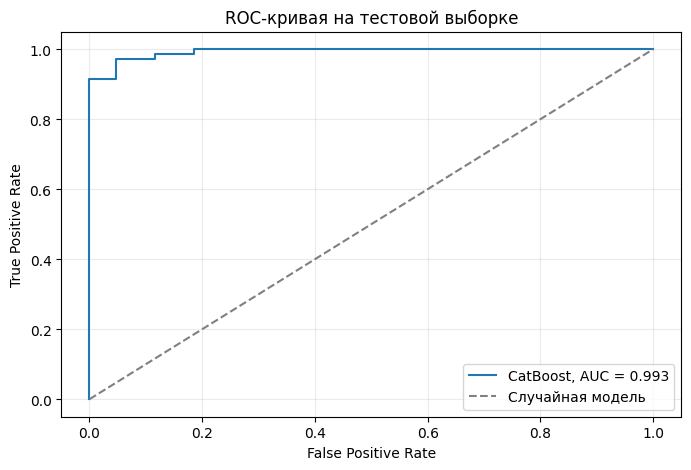

In [4]:
test_probability = binary_model.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= 0.5).astype(int)

metrics = pd.Series({
    "ROC AUC": roc_auc_score(y_test, test_probability),
    "Accuracy": accuracy_score(y_test, test_prediction),
    "Precision": precision_score(y_test, test_prediction),
    "Recall": recall_score(y_test, test_prediction),
    "F1": f1_score(y_test, test_prediction),
})
print(metrics.round(4).to_string())
print("\nМатрица ошибок:\n", confusion_matrix(y_test, test_prediction))

fpr, tpr, _ = roc_curve(y_test, test_probability)
plt.plot(fpr, tpr, label=f"CatBoost, AUC = {metrics['ROC AUC']:.3f}")
plt.plot([0, 1], [0, 1], "--", color="grey", label="Случайная модель")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривая на тестовой выборке")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 6. Категориальные признаки и пропуски

Создадим синтетический набор об оттоке клиентов. В нём будут:

- числовые признаки: возраст, срок обслуживания, платёж, число обращений;
- категориальные: регион, тариф, договор, устройство;
- бинарный признак автоплатежа;
- пропуски в числовом и категориальном столбцах.

Данные искусственные, поэтому выводы относятся только к демонстрации API, а не к реальному бизнесу.

In [5]:
n = 2500
churn_data = pd.DataFrame({
    "age": rng.integers(18, 81, n),
    "tenure_months": rng.integers(0, 73, n),
    "monthly_fee": np.clip(rng.normal(1200, 300, n), 200, None).round(2),
    "support_calls": rng.poisson(1.2, n),
    "region": rng.choice(["север", "юг", "восток", "запад"], n),
    "tariff": rng.choice(["базовый", "стандарт", "премиум"], n, p=[0.35, 0.45, 0.20]),
    "contract": rng.choice(["месячный", "годовой", "двухлетний"], n, p=[0.55, 0.30, 0.15]),
    "device": rng.choice(["android", "ios", "другое"], n, p=[0.55, 0.35, 0.10]),
    "has_autopay": rng.integers(0, 2, n),
})

logit = (
    -1.0
    + 0.90 * (churn_data["contract"] == "месячный")
    - 0.55 * (churn_data["contract"] == "двухлетний")
    + 0.50 * (churn_data["tariff"] == "базовый")
    - 0.35 * (churn_data["tariff"] == "премиум")
    + 0.30 * churn_data["support_calls"]
    - 0.020 * churn_data["tenure_months"]
    + 0.55 * (churn_data["monthly_fee"] > 1500)
    - 0.45 * churn_data["has_autopay"]
    + rng.normal(0, 0.30, n)
)
churn_probability = expit(logit)
churn_data["churn"] = rng.binomial(1, churn_probability)

# CatBoost поддерживает NaN в числовых признаках.
churn_data.loc[rng.random(n) < 0.03, "monthly_fee"] = np.nan

# Для категориального признака пропуск обозначим отдельной строкой.
churn_data.loc[rng.random(n) < 0.04, "region"] = "неизвестно"

features = [column for column in churn_data.columns if column != "churn"]
cat_features = ["region", "tariff", "contract", "device"]

print("Доля оттока:", round(float(churn_data["churn"].mean()), 3))
churn_data.head()

Доля оттока: 0.296


,age,tenure_months,monthly_fee,support_calls,region,tariff,contract,device,has_autopay,churn
0,23,51,1087.17,1,восток,базовый,месячный,ios,0,1
1,66,7,1062.58,1,север,базовый,месячный,android,1,0
2,59,54,1430.69,1,север,базовый,годовой,ios,0,0
3,45,7,1445.73,2,запад,стандарт,месячный,android,1,1
4,45,3,1039.47,1,запад,стандарт,месячный,ios,1,1


### Передаём категории через Pool

`Pool` — контейнер CatBoost для признаков, цели и дополнительной информации. Названия категориальных столбцов передаём в `cat_features`. Можно также указать их позиции, но имена обычно удобнее и менее хрупки.

**Не нужно:**

- масштабировать числовые признаки;
- делать one-hot encoding;
- кодировать категории случайными числами: это может создать ложный порядок категорий.

**Нужно:** привести категориальные значения к согласованному виду, например не смешивать `"Москва"`, `"москва"` и `" Москва "`, если это одна категория.

In [6]:
X_cat = churn_data[features]
y_cat = churn_data["churn"]

X_cat_train, X_cat_temp, y_cat_train, y_cat_temp = train_test_split(
    X_cat, y_cat, test_size=0.40, random_state=SEED, stratify=y_cat
)
X_cat_valid, X_cat_test, y_cat_valid, y_cat_test = train_test_split(
    X_cat_temp, y_cat_temp, test_size=0.50, random_state=SEED, stratify=y_cat_temp
)

train_pool = Pool(X_cat_train, y_cat_train, cat_features=cat_features)
valid_pool = Pool(X_cat_valid, y_cat_valid, cat_features=cat_features)
test_pool = Pool(X_cat_test, cat_features=cat_features)

cat_model = CatBoostClassifier(
    iterations=700,
    learning_rate=0.05,
    depth=6,
    l2_leaf_reg=5,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=SEED,
    verbose=False,
)
cat_model.fit(
    train_pool,
    eval_set=valid_pool,
    early_stopping_rounds=60,
    use_best_model=True,
)

cat_probability = cat_model.predict_proba(test_pool)[:, 1]
cat_prediction = (cat_probability >= 0.5).astype(int)

print(f"Лучшая итерация: {cat_model.get_best_iteration()}")
print(f"ROC AUC: {roc_auc_score(y_cat_test, cat_probability):.4f}")
print(f"PR AUC:  {average_precision_score(y_cat_test, cat_probability):.4f}")
print("\nОтчёт по классам:\n")
print(classification_report(y_cat_test, cat_prediction, digits=3))

Лучшая итерация: 95
ROC AUC: 0.7273
PR AUC:  0.5204

Отчёт по классам:

              precision    recall  f1-score   support

           0      0.735     0.960     0.833       352
           1      0.650     0.176     0.277       148

    accuracy                          0.728       500
   macro avg      0.692     0.568     0.555       500
weighted avg      0.710     0.728     0.668       500



### Важность признаков

`PredictionValuesChange` показывает, насколько в среднем меняется прогноз при использовании признака в разбиениях. Это полезно для первичного анализа модели, но:

- высокая важность не доказывает причинно-следственную связь;
- коррелированные признаки могут делить важность между собой;
- важность описывает поведение модели, а не обязательно устройство реального мира.

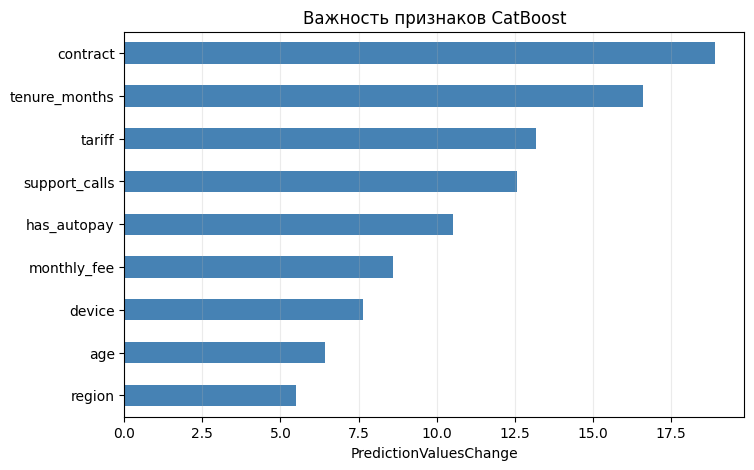

,Важность
contract,18.91
tenure_months,16.60
tariff,13.19
support_calls,12.58
has_autopay,10.53
monthly_fee,8.61
device,7.65
age,6.43
region,5.49


In [7]:
importance = pd.Series(
    cat_model.get_feature_importance(),
    index=features,
).sort_values(ascending=False)

importance.sort_values().plot(kind="barh", color="steelblue")
plt.title("Важность признаков CatBoost")
plt.xlabel("PredictionValuesChange")
plt.ylabel("")
plt.grid(axis="x", alpha=0.25)
plt.show()

importance.round(2).to_frame("Важность")

## 7. Регрессия

В регрессии цель — число. Используем встроенный набор `diabetes` и `CatBoostRegressor`.

- **MAE** — средняя абсолютная ошибка, легко интерпретируется в единицах цели;
- **RMSE** сильнее штрафует большие ошибки;
- **$R^2$** показывает долю объяснённой дисперсии относительно простого среднего прогноза. Чем ближе к 1, тем лучше; на новых данных значение может быть отрицательным.

Здесь функция потерь — `RMSE`, а дополнительная контрольная метрика — `MAE`.

Лучшая итерация: 189
MAE:  44.577
RMSE: 54.615
R²:   0.484


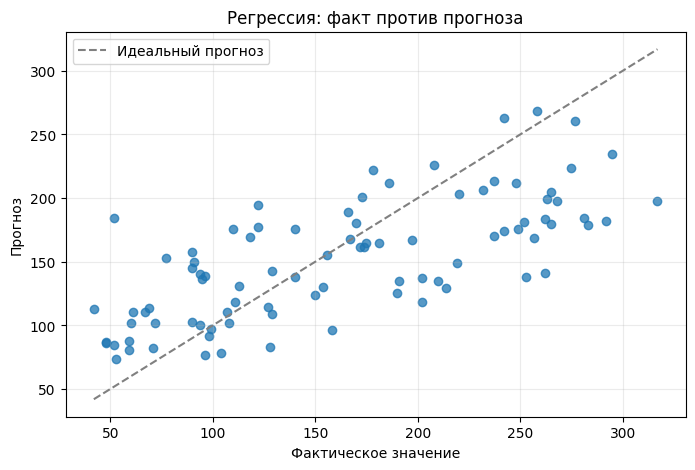

In [8]:
regression_data = load_diabetes(as_frame=True)
X_reg = regression_data.data
y_reg = regression_data.target

X_reg_train, X_reg_temp, y_reg_train, y_reg_temp = train_test_split(
    X_reg, y_reg, test_size=0.40, random_state=SEED
)
X_reg_valid, X_reg_test, y_reg_valid, y_reg_test = train_test_split(
    X_reg_temp, y_reg_temp, test_size=0.50, random_state=SEED
)

reg_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.04,
    depth=5,
    l2_leaf_reg=5,
    loss_function="RMSE",
    eval_metric="MAE",
    random_seed=SEED,
    verbose=False,
)
reg_model.fit(
    X_reg_train,
    y_reg_train,
    eval_set=(X_reg_valid, y_reg_valid),
    early_stopping_rounds=70,
    use_best_model=True,
)

reg_prediction = reg_model.predict(X_reg_test)
rmse = mean_squared_error(y_reg_test, reg_prediction) ** 0.5
mae = mean_absolute_error(y_reg_test, reg_prediction)
r2 = r2_score(y_reg_test, reg_prediction)

print(f"Лучшая итерация: {reg_model.get_best_iteration()}")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

plt.scatter(y_reg_test, reg_prediction, alpha=0.75)
limits = [min(y_reg_test.min(), reg_prediction.min()), max(y_reg_test.max(), reg_prediction.max())]
plt.plot(limits, limits, "--", color="grey", label="Идеальный прогноз")
plt.xlabel("Фактическое значение")
plt.ylabel("Прогноз")
plt.title("Регрессия: факт против прогноза")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 8. Многоклассовая классификация

Если классов больше двух, используется `loss_function="MultiClass"`. Метод `predict_proba` возвращает по одной вероятности для каждого класса.

Для несбалансированных классов одной accuracy недостаточно: полезно смотреть **macro-F1**, матрицу ошибок и отчёт по каждому классу. Macro-F1 усредняет F1 по классам с одинаковым весом, поэтому редкий класс не «теряется» среди частых.

Accuracy: 0.933
Macro-F1: 0.933
Форма матрицы вероятностей: (30, 3)

               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



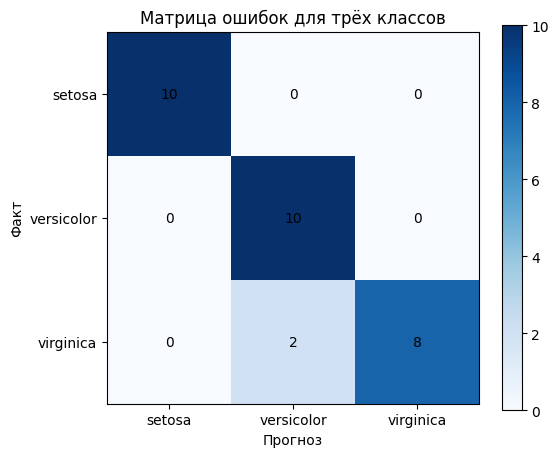

In [9]:
iris = load_iris(as_frame=True)
X_iris = iris.data
y_iris = iris.target

X_iris_train, X_iris_temp, y_iris_train, y_iris_temp = train_test_split(
    X_iris, y_iris, test_size=0.40, random_state=SEED, stratify=y_iris
)
X_iris_valid, X_iris_test, y_iris_valid, y_iris_test = train_test_split(
    X_iris_temp, y_iris_temp, test_size=0.50, random_state=SEED, stratify=y_iris_temp
)

multiclass_model = CatBoostClassifier(
    iterations=400,
    learning_rate=0.07,
    depth=5,
    loss_function="MultiClass",
    eval_metric="TotalF1",
    random_seed=SEED,
    verbose=False,
)
multiclass_model.fit(
    X_iris_train,
    y_iris_train,
    eval_set=(X_iris_valid, y_iris_valid),
    early_stopping_rounds=50,
    use_best_model=True,
)

multiclass_prediction = multiclass_model.predict(X_iris_test).ravel()
multiclass_probability = multiclass_model.predict_proba(X_iris_test)

print(f"Accuracy: {accuracy_score(y_iris_test, multiclass_prediction):.3f}")
print(f"Macro-F1: {f1_score(y_iris_test, multiclass_prediction, average='macro'):.3f}")
print("Форма матрицы вероятностей:", multiclass_probability.shape)
print("\n", classification_report(y_iris_test, multiclass_prediction, target_names=iris.target_names))

cm = confusion_matrix(y_iris_test, multiclass_prediction)
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), iris.target_names)
ax.set_yticks(range(3), iris.target_names)
ax.set_xlabel("Прогноз")
ax.set_ylabel("Факт")
ax.set_title("Матрица ошибок для трёх классов")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center")
fig.colorbar(image, ax=ax)
plt.show()

## 9. Ранжирование

В ранжировании модель должна не просто оценить объект, а правильно упорядочить объекты **внутри группы**. Примеры групп:

- один поисковый запрос и его документы;
- один пользователь и кандидаты для рекомендации;
- один товарный запрос и список товаров.

Для этого используют `CatBoostRanker`, а в `Pool` передают `group_id`.

### Главное правило разбиения

**Нельзя случайно разбрасывать строки одной группы между train и test.** Группы нужно разделять целиком, иначе валидация может оказаться нечестной.

Ниже создадим искусственные запросы, у каждого из которых одинаковое число документов. Целевая переменная — целочисленная релевантность от 0 до 4.

In [10]:
n_queries = 100
documents_per_query = 12
n_rows = n_queries * documents_per_query

query_ids = np.repeat(np.arange(n_queries), documents_per_query)
rank_X = pd.DataFrame({
    "title_match": rng.random(n_rows),
    "text_match": rng.random(n_rows),
    "past_clicks": rng.poisson(2, n_rows),
    "document_length": rng.integers(100, 3000, n_rows),
})
rank_score = (
    4.0 * rank_X["title_match"]
    + 3.0 * rank_X["text_match"]
    + 0.35 * rank_X["past_clicks"]
    + rng.normal(0, 0.8, n_rows)
)
# Квантили превращаем в пять уровней релевантности.
rank_y = pd.qcut(rank_score, q=5, labels=False).astype(int).to_numpy()

train_queries = np.arange(0, 70)
valid_queries = np.arange(70, 85)
test_queries = np.arange(85, 100)

def ranking_pool(queries, with_target=True):
    mask = np.isin(query_ids, queries)
    return Pool(
        rank_X.loc[mask].reset_index(drop=True),
        label=rank_y[mask] if with_target else None,
        group_id=query_ids[mask],
    )

rank_train = ranking_pool(train_queries)
rank_valid = ranking_pool(valid_queries)
rank_test = ranking_pool(test_queries)

ranker = CatBoostRanker(
    iterations=350,
    learning_rate=0.06,
    depth=6,
    loss_function="YetiRank",
    eval_metric="NDCG:top=5",
    random_seed=SEED,
    verbose=False,
)
ranker.fit(rank_train, eval_set=rank_valid, early_stopping_rounds=50, use_best_model=True)

rank_prediction = ranker.predict(rank_test)
true_by_query = rank_y[np.isin(query_ids, test_queries)].reshape(len(test_queries), documents_per_query)
pred_by_query = rank_prediction.reshape(len(test_queries), documents_per_query)
ndcg_values = [
    ndcg_score([actual], [predicted], k=5)
    for actual, predicted in zip(true_by_query, pred_by_query)
]

print(f"Лучшая итерация: {ranker.get_best_iteration()}")
print(f"Средний NDCG@5 на тестовых запросах: {np.mean(ndcg_values):.3f}")
print("Первые 5 документов по убыванию прогноза:", np.argsort(-pred_by_query[0])[:5].tolist())

Лучшая итерация: 78
Средний NDCG@5 на тестовых запросах: 0.957
Первые 5 документов по убыванию прогноза: [6, 0, 10, 3, 1]


## 10. Кросс-валидация и настройка параметров

### Кросс-валидация

Одно разбиение может дать случайно оптимистичную или пессимистичную оценку. При $k$-fold кросс-валидации данные делятся на $k$ частей: модель по очереди обучается на $k-1$ частях и проверяется на оставшейся.

Функция `catboost.cv` возвращает таблицу метрик по итерациям. Для классификации здесь используем стратификацию. В реальных задачах схема зависит от структуры данных:

- временные данные — проверка на более позднем периоде;
- несколько строк одного пользователя — групповое разбиение;
- ранжирование — разбиение по группам.

In [11]:
cv_pool = Pool(X_cat, y_cat, cat_features=cat_features)
cv_params = {
    "iterations": 350,
    "learning_rate": 0.06,
    "depth": 6,
    "l2_leaf_reg": 5,
    "loss_function": "Logloss",
    "eval_metric": "AUC",
    "random_seed": SEED,
    "verbose": False,
}
cv_results = cv(
    params=cv_params,
    pool=cv_pool,
    fold_count=3,
    stratified=True,
    partition_random_seed=SEED,
    early_stopping_rounds=40,
)

best_cv_row = cv_results.loc[cv_results["test-AUC-mean"].idxmax()]
print(f"Лучшая итерация по среднему CV AUC: {int(best_cv_row['iterations'])}")
print(f"Средний test AUC: {best_cv_row['test-AUC-mean']:.4f}")
print(f"Стандартное отклонение AUC: {best_cv_row['test-AUC-std']:.4f}")
cv_results.tail(3)

Training on fold [0/3]

bestTest = 0.7047362214
bestIteration = 72

Training on fold [1/3]



bestTest = 0.6998970582
bestIteration = 30

Training on fold [2/3]

bestTest = 0.7059457518
bestIteration = 67

Лучшая итерация по среднему CV AUC: 43
Средний test AUC: 0.7012
Стандартное отклонение AUC: 0.0036


,iterations,test-AUC-mean,test-AUC-std,test-Logloss-mean,test-Logloss-std,train-Logloss-mean,train-Logloss-std
110,110,0.698660,0.004385,0.555936,0.001068,0.486930,0.010947
111,111,0.698657,0.004384,0.555950,0.001045,0.486776,0.011103
112,112,0.698657,0.004384,0.555950,0.001044,0.486771,0.011109


### Что настраивать в первую очередь

Не пытайтесь перебрать всё сразу. Начните с базовой модели и меняйте небольшое число параметров.

| Ситуация | Что попробовать |
|---|---|
| Модель переобучается | уменьшить `depth`, увеличить `l2_leaf_reg`, уменьшить `learning_rate`, использовать `early_stopping_rounds` |
| Модель недообучается | увеличить `iterations`, умеренно увеличить `depth`, добавить информативные признаки |
| Обучение слишком быстро останавливается | проверить метрику и валидацию, увеличить `early_stopping_rounds`, уменьшить `learning_rate` |
| Сильный дисбаланс классов | выбрать подходящую метрику, попробовать `class_weights` или `auto_class_weights`, настроить порог |
| Категории с высокой кардинальностью | проверить качество очистки, частоты категорий, ограничения памяти и параметры обработки категорий |

### Полезные параметры регуляризации

- `depth` — сложность дерева;
- `l2_leaf_reg` — регуляризация листьев;
- `random_strength` — случайность выбора разбиений;
- `bagging_temperature` — интенсивность байесовского бутстрэпа;
- `subsample` — доля объектов, если выбран соответствующий тип бутстрэпа.

Подбор выполняйте по валидации или кросс-валидации. Тестовую выборку не используйте для выбора гиперпараметров и порога.

## 11. Сохранение, загрузка и прогноз

Модель CatBoost можно сохранить в бинарном формате `.cbm`. При загрузке важно сохранить тот же порядок столбцов и список категориальных признаков, который использовался при обучении.

В примере используется временная папка: она автоматически удаляется после проверки.

In [12]:
with tempfile.TemporaryDirectory() as temporary_directory:
    model_path = Path(temporary_directory) / "churn_model.cbm"
    cat_model.save_model(model_path)

    loaded_model = CatBoostClassifier()
    loaded_model.load_model(model_path)

    original_probability = cat_model.predict_proba(test_pool)[:, 1]
    restored_probability = loaded_model.predict_proba(test_pool)[:, 1]
    print("Прогнозы совпадают:", np.allclose(original_probability, restored_probability))

# Пример прогноза для одного нового клиента.
new_client = X_cat_test.iloc[[0]].copy()
new_client_pool = Pool(new_client, cat_features=cat_features)
churn_risk = cat_model.predict_proba(new_client_pool)[0, 1]
print(f"Оценка вероятности оттока: {churn_risk:.3f}")
new_client

Прогнозы совпадают: True
Оценка вероятности оттока: 0.518


,age,tenure_months,monthly_fee,support_calls,region,tariff,contract,device,has_autopay
2247,29,18,977.06,0,север,базовый,месячный,android,0


## 12. Типичные ошибки и практические рекомендации

### Ошибки

1. **Тест участвует в настройке.**  
   Если выбирать параметры по test, итоговая оценка станет оптимистичной. Для настройки нужна validation или кросс-валидация.

2. **Категориальные признаки не указаны.**  
   Без `cat_features` CatBoost не сможет применить к ним специальную обработку категорий, а строковые значения могут вызвать ошибку.

3. **Пропуски в категориях.**  
   Замените их осмысленной строкой, например `"неизвестно"`. Числовые `NaN` можно оставить.

4. **Утечка целевой информации.**  
   Признак, который становится известен только после наступления события, нельзя использовать для его предсказания. Ordered boosting не защищает от такой утечки в исходных данных.

5. **Неправильная схема разбиения.**  
   Для времени, пользователей и поисковых групп обычный случайный split по строкам может быть некорректен.

6. **Сравнение моделей по accuracy при дисбалансе.**  
   Выбирайте метрику по задаче: PR AUC, recall при ограничении на precision, F1, Logloss или бизнес-метрику.

7. **Интерпретация важности как причинности.**  
   Важность признака объясняет вклад в прогнозы модели, но не доказывает причинный эффект.

### Минимальный шаблон для своей задачи

```python
from catboost import CatBoostClassifier, Pool

cat_features = ["название_категориального_столбца"]
train_pool = Pool(X_train, y_train, cat_features=cat_features)
valid_pool = Pool(X_valid, y_valid, cat_features=cat_features)

model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    early_stopping_rounds=50,
    random_seed=42,
    verbose=100,
)
model.fit(train_pool, eval_set=valid_pool)
probability = model.predict_proba(
    Pool(X_test, cat_features=cat_features)
)[:, 1]
```

### Порядок работы над реальным проектом

1. Сформулировать цель, момент прогноза и доступные на этот момент признаки.
2. Выбрать метрику и простую базовую модель.
3. Построить корректную схему валидации.
4. Очистить категории и проверить пропуски, дубликаты и утечки.
5. Обучить CatBoost с ранней остановкой.
6. Проанализировать ошибки по сегментам, а не только среднюю метрику.
7. Настроить несколько ключевых параметров и порог решения.
8. Проверить финальную модель на отложенных данных и сохранить её вместе со схемой признаков.

## Упражнения для самостоятельной практики

1. В бинарной классификации сравните `depth=4`, `6` и `8`. Как меняются число итераций и ROC AUC на validation?
2. Для модели оттока найдите на validation порог, максимизирующий F1, а затем один раз оцените его на test.
3. Добавьте в синтетические данные категориальный признак с 100 редкими категориями и посмотрите на качество и время обучения.
4. Сравните CatBoost с логистической регрессией на одинаковых разбиениях. Для логистической регрессии заранее закодируйте категории и обработайте пропуски.
5. В регрессии сравните `RMSE` и `MAE` как функции потерь. Объясните различия в ошибках.

## Краткое резюме

- CatBoost строит ансамбль деревьев, где каждое следующее дерево уменьшает ошибку текущей модели.
- Основные классы: `CatBoostClassifier`, `CatBoostRegressor`, `CatBoostRanker`.
- Категориальные столбцы передаются через `cat_features`; масштабирование и one-hot encoding обычно не нужны.
- `Pool` объединяет признаки, цель, категории и, для ранжирования, группы.
- Для обучения используйте train/validation/test или корректную кросс-валидацию, раннюю остановку и подходящую метрику.
- Качество определяется не только библиотекой: данные, отсутствие утечек и схема проверки не менее важны.

**Официальная документация:** [catboost.ai/docs](https://catboost.ai/docs/).